# Accessing CMIP6 data from the Pangeo cloud archive

The [Pangeo CMIP6 cloud archive](https://pangeo-data.github.io/pangeo-cmip6-cloud/accessing_data.html) hosts CMIP6 climate model output as analysis-ready, cloud-optimised (ARCO) Zarr stores on Google Cloud Storage. No account, download or HPC access is needed: PyEarthTools opens the stores lazily, so only the data you use is transferred.

The `PangeoCMIP6` accessor, in the `site_archive_pangeo` package, is derived from the PyEarthTools `ArchiveIndex` class. It looks up each variable in the Pangeo catalogue and opens its Zarr store, so it is used like any other PyEarthTools data accessor.

Install the package from the monorepo with `pip install -e packages/third_party/pangeo_site_archive`.

### Set up imports for demo

In [1]:
import matplotlib.pyplot
import cartopy.crs
import numpy

import pyearthtools.data
from site_archive_pangeo import PangeoCMIP6

## Discover the available data

The catalogue lists every variable of every model run in the archive. `PangeoCMIP6.catalog()` returns it as a pandas `DataFrame`, so the usual pandas filtering shows what is available. The catalogue is a large CSV file, so the first read takes a moment.

In [2]:
catalog = PangeoCMIP6.catalog()
catalog.head()

,source_id,experiment_id,member_id,table_id,variable_id,grid_label,zstore,version
0,CMCC-CM2-HR4,highresSST-present,r1i1p1f1,Amon,ps,gn,gs://cmip6/CMIP6/HighResMIP/CMCC/CMCC-CM2-HR4/...,20170706
1,CMCC-CM2-HR4,highresSST-present,r1i1p1f1,Amon,rsds,gn,gs://cmip6/CMIP6/HighResMIP/CMCC/CMCC-CM2-HR4/...,20170706
2,CMCC-CM2-HR4,highresSST-present,r1i1p1f1,Amon,rlus,gn,gs://cmip6/CMIP6/HighResMIP/CMCC/CMCC-CM2-HR4/...,20170706
3,CMCC-CM2-HR4,highresSST-present,r1i1p1f1,Amon,rlds,gn,gs://cmip6/CMIP6/HighResMIP/CMCC/CMCC-CM2-HR4/...,20170706
4,CMCC-CM2-HR4,highresSST-present,r1i1p1f1,Amon,psl,gn,gs://cmip6/CMIP6/HighResMIP/CMCC/CMCC-CM2-HR4/...,20170706


Each row is one variable of one model run. Here we count, for each experiment, how many models provide monthly near-surface air temperature (`tas` in the `Amon` table).

In [3]:
monthly_tas = catalog[(catalog['variable_id'] == 'tas') & (catalog['table_id'] == 'Amon')]
monthly_tas.groupby('experiment_id')['source_id'].nunique().sort_values(ascending=False).head(10)

experiment_id
piControl         64
historical        64
1pctCO2           59
abrupt-4xCO2      59
ssp585            47
amip              46
ssp245            46
ssp126            44
ssp370            42
piClim-control    19
Name: source_id, dtype: int64

## Set up the accessor

An accessor selects one model run: the model (`source_id`), the experiment (`experiment_id`), the ensemble member (`member_id`, default `r1i1p1f1`) and the table (`table_id`, default `Amon`, monthly atmosphere). Here we use the `historical` experiment of the `CanESM5` model.

Creating the accessor does not read the catalogue or any data.

In [4]:
index = PangeoCMIP6(['tas'], source_id='CanESM5', experiment_id='historical')
index

PangeoCMIP6
	Description                    Pangeo CMIP6 analysis-ready, cloud-optimised data accessor
		 Documentation                  'https://pangeo-data.github.io/pangeo-cmip6-cloud/accessing_data.html'


	Initialisation                 
		 catalog                        'https://storage.googleapis.com/cmip6/pangeo-cmip6.csv'
		 experiment_id                  'historical'
		 grid_label                     None
		 member_id                      'r1i1p1f1'
		 source_id                      'CanESM5'
		 table_id                       'Amon'
		 variables                      ['tas']
	Transforms                     
		 StandardCoordinateNames        {'latitude': "['lat', 'Latitude', 'yt_ocean', 'yt']", 'longitude': "['lon', 'Longitude', 'xt_ocean', 'xt']", 'replacement_dictionary': 'None', 'time': "['Time']"}
		 Trim                           {'__args': '()', 'variables': "['tas']"}

## Retrieve data

`retrieve` looks up the Zarr store of each variable and selects the requested time. The result is lazy, so the values are only downloaded when they are used.

In [5]:
data = index.retrieve('2000-01')
data

<xarray.Dataset> Size: 34kB
Dimensions:    (time: 1, latitude: 64, longitude: 128)
Coordinates:
  * time       (time) object 8B 2000-01-16 12:00:00
  * latitude   (latitude) float64 512B -87.86 -85.1 -82.31 ... 82.31 85.1 87.86
  * longitude  (longitude) float64 1kB 0.0 2.812 5.625 ... 351.6 354.4 357.2
    height     float64 8B ...
Data variables:
    tas        (time, latitude, longitude) float32 33kB dask.array<chunksize=(1, 64, 128), meta=np.ndarray>
Attributes: (12/54)
    CCCma_model_hash:            3dedf95315d603326fde4f5340dc0519d80d10c0
    CCCma_parent_runid:          rc3-pictrl
    CCCma_pycmor_hash:           33c30511acc319a98240633965a04ca99c26427e
    CCCma_runid:                 rc3.1-his01
    Conventions:                 CF-1.7 CMIP-6.2
    YMDH_branch_time_in_child:   1850:01:01:00
    ...                          ...
    title:                       CanESM5 output prepared for CMIP6
    tracking_id:                 hdl:21.14100/872062df-acae-499b-aa0f-9eaca76...
    variable_id:                 tas
    variant_label:               r1i1p1f1
    version:                     v20190429
    status:                      2019-10-25;created;by nhn2@columbia.edu

## Visualise the data

Plot the near-surface air temperature of January 2000 on a map. CMIP6 temperatures are in kelvin, so we convert to degrees Celsius. The model longitudes run from 0 to 360, so the map is centred on 180 degrees.

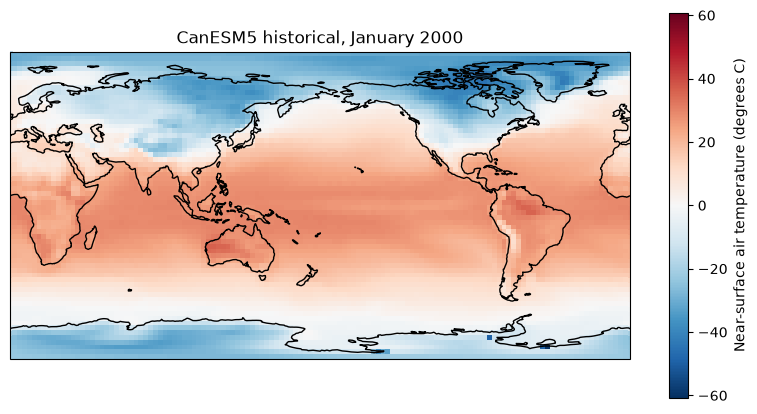

In [6]:
temperature = data['tas'].squeeze() - 273.15

fig = matplotlib.pyplot.figure(figsize=(10, 5))
ax = matplotlib.pyplot.axes(projection=cartopy.crs.PlateCarree(central_longitude=180))
temperature.plot(
    ax=ax,
    transform=cartopy.crs.PlateCarree(),
    cmap='RdBu_r',
    cbar_kwargs={'label': 'Near-surface air temperature (degrees C)'},
)
ax.coastlines()
ax.set_title('CanESM5 historical, January 2000');

## Load every time of a variable

A Zarr store holds all times of a variable, so the accessor ignores the requested time when it looks the store up and selects the time afterwards. `filesystem` shows the store that is opened.

In [7]:
index.filesystem('2000-01')

{'tas': 'gs://cmip6/CMIP6/CMIP/CCCma/CanESM5/historical/r1i1p1f1/Amon/tas/gn/v20190429/'}

`load` opens that store lazily with all of its times. Here we use it to plot the area-weighted global mean temperature of the whole historical run, averaged over each year. Only the `tas` data is downloaded, which takes a short while.

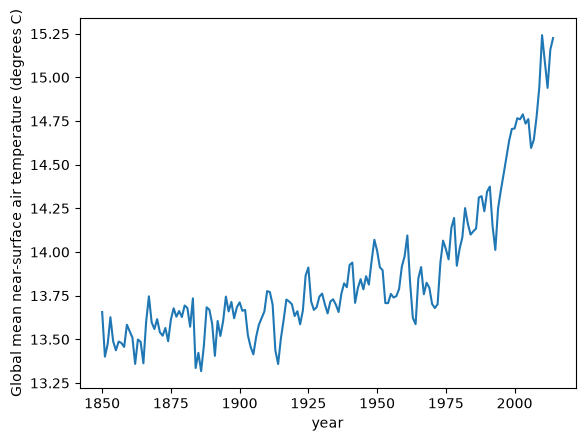

In [8]:
full = index.load(index.filesystem('2000-01'))

weights = numpy.cos(numpy.deg2rad(full['lat']))
global_mean = full['tas'].weighted(weights).mean(('lat', 'lon')) - 273.15

annual_mean = global_mean.groupby('time.year').mean().drop_vars('height', errors='ignore')
annual_mean.plot()
matplotlib.pyplot.ylabel('Global mean near-surface air temperature (degrees C)');

## Several variables and grids

Pass a list of variables to retrieve several at once. Each variable is looked up in the catalogue and the newest version is used.

In [9]:
multi_index = PangeoCMIP6(['tas', 'pr'], source_id='CanESM5', experiment_id='historical')
multi_index.retrieve('2000-01')

<xarray.Dataset> Size: 67kB
Dimensions:    (time: 1, latitude: 64, longitude: 128)
Coordinates:
  * time       (time) object 8B 2000-01-16 12:00:00
  * latitude   (latitude) float64 512B -87.86 -85.1 -82.31 ... 82.31 85.1 87.86
  * longitude  (longitude) float64 1kB 0.0 2.812 5.625 ... 351.6 354.4 357.2
    height     float64 8B ...
Data variables:
    tas        (time, latitude, longitude) float32 33kB dask.array<chunksize=(1, 64, 128), meta=np.ndarray>
    pr         (time, latitude, longitude) float32 33kB dask.array<chunksize=(1, 64, 128), meta=np.ndarray>
Attributes: (12/54)
    CCCma_model_hash:            3dedf95315d603326fde4f5340dc0519d80d10c0
    CCCma_parent_runid:          rc3-pictrl
    CCCma_pycmor_hash:           33c30511acc319a98240633965a04ca99c26427e
    CCCma_runid:                 rc3.1-his01
    Conventions:                 CF-1.7 CMIP-6.2
    YMDH_branch_time_in_child:   1850:01:01:00
    ...                          ...
    title:                       CanESM5 output prepared for CMIP6
    tracking_id:                 hdl:21.14100/872062df-acae-499b-aa0f-9eaca76...
    variable_id:                 tas
    variant_label:               r1i1p1f1
    version:                     v20190429
    status:                      2019-10-25;created;by nhn2@columbia.edu

Some variables exist on more than one grid. The accessor then raises an error asking for a `grid_label`, for example `grid_label='gn'` for the native model grid or `grid_label='gr'` for a regridded one.

Scalar coordinates that differ between variables, such as `height` (2 m for `tas`, 10 m for `uas`), are dropped when the variables are combined.